# 01 · Data Audit — Olist Delivery Promise Risk

**Goal of this notebook (Stage 1).** Inspect all nine source tables *before* any modelling. For each one we check its schema, size, keys, granularity, missingness, relationships and data quality. We then establish which orders have an observable outcome and recommend the smallest set of tables the primary task needs.

Rules followed here:
* Nothing is joined blindly. Relationships are measured from key counts, and no join result is materialised just to look at it.
* Every number is computed from the supplied files. Figures from the proposal are listed separately as *prior estimates* (section 11).
* Selective loading: only the columns needed are read, with compact dtypes. The 1M-row geolocation table is loaded once for auditing and then discarded.

In [1]:
import sys, time, re, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil
from olist import config as C
from olist.io import load, file_inventory
from olist.audit import profile, table_summary, key_uniqueness, relationship, timestamp_anomalies, late_labels
from olist.geo import build_zip_map, lookup_coords

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
proc = psutil.Process(); T0 = time.perf_counter()
def rss(): return f"{proc.memory_info().rss/1e6:,.0f} MB"
print("pandas", pd.__version__, "| data dir:", C.DATA_DIR, "| RSS", rss())

pandas 2.3.2 | data dir: D:\B.Tech\Sem - 5\ML\Innovative Assignment\Dataset | RSS 157 MB


## 1. File inventory
Row counts come from line counting rather than a full parse. The reviews file is the exception: its free-text comments span several physical lines, so it is parsed with a single column.

In [2]:
inv = file_inventory()
inv

,file,size_mb,rows,n_cols
table,,,,
orders,olist_orders_dataset.csv,16.03,99441,8
customers,olist_customers_dataset.csv,9.03,99441,5
items,olist_order_items_dataset.csv,14.62,112650,7
payments,olist_order_payments_dataset.csv,5.78,103886,5
reviews,olist_order_reviews_dataset.csv,14.45,99224,7
products,olist_products_dataset.csv,2.38,32951,9
sellers,olist_sellers_dataset.csv,0.17,3095,4
geolocation,olist_geolocation_dataset.csv,61.27,1000163,5
translation,product_category_name_translation.csv,0.00,71,2


In [3]:
print(f"Total on disk: {inv.size_mb.sum():.1f} MB; geolocation alone: {inv.loc['geolocation','size_mb']} MB "
      f"({inv.loc['geolocation','size_mb']/inv.size_mb.sum():.0%}) for {inv.loc['geolocation','rows']:,} rows")

Total on disk: 123.7 MB; geolocation alone: 61.27 MB (50%) for 1,000,163 rows


## 2. Raw timestamp formats
We first check which format each timestamp column *actually* uses, before trusting any parser. Every digit is replaced by `9` and the resulting patterns are counted.

In [4]:
def patterns(path, cols):
    raw = pd.read_csv(path, usecols=cols, dtype=str)
    return {c: raw[c].map(lambda x: "NA" if pd.isna(x) else re.sub(r"\d", "9", x)).value_counts().to_dict() for c in cols}

fmt_rows = []
for t in ["orders", "items", "reviews"]:
    cols, fmt = C.DATE_COLS[t]
    for col, pats in patterns(C.DATA_DIR / C.FILES[t], cols).items():
        fmt_rows.append({"table": t, "column": col, "patterns": pats, "parser_format": fmt})
pd.DataFrame(fmt_rows)

,table,column,patterns,parser_format
0,orders,order_purchase_timestamp,{'99-99-9999 99:99': 99441},%d-%m-%Y %H:%M
1,orders,order_approved_at,"{'99-99-9999 99:99': 99281, 'NA': 160}",%d-%m-%Y %H:%M
2,orders,order_delivered_carrier_date,"{'99-99-9999 99:99': 97658, 'NA': 1783}",%d-%m-%Y %H:%M
3,orders,order_delivered_customer_date,"{'99-99-9999 99:99': 96476, 'NA': 2965}",%d-%m-%Y %H:%M
4,orders,order_estimated_delivery_date,{'99-99-9999 99:99': 99441},%d-%m-%Y %H:%M
5,items,shipping_limit_date,{'99-99-9999 99:99': 112650},%d-%m-%Y %H:%M
6,reviews,review_creation_date,{'9999-99-99 99:99:99': 99224},ISO8601
7,reviews,review_answer_timestamp,{'9999-99-99 99:99:99': 99224},ISO8601


**Finding.** `orders` and `order_items` use day-first `DD-MM-YYYY HH:MM` with the seconds dropped. This is **not** the ISO format of the public Kaggle release. `reviews` uses ISO dates, and almost all of them are date-only.

**Implication.**
* All loaders pass an explicit `format=` (`olist.io.parse_dates`), which raises on any mismatch. A test checks that `02-10-2017` parses as 2 October. Pandas' inference would silently treat it as 10 February for ambiguous days.
* Timing precision is one minute. That is ample for day-level targets.

## 3. Load all tables (selective columns, compact dtypes) and profile them
Review free text (title/message) is **not** loaded: it is post-delivery and is not used by the primary task.

In [5]:
t = time.perf_counter()
T = {name: load(name) for name in ["orders", "customers", "items", "payments", "reviews", "products", "sellers", "translation"]}
geo_full = pd.read_csv(C.DATA_DIR / C.FILES["geolocation"],
                       dtype={"geolocation_zip_code_prefix": "string", "geolocation_city": "category", "geolocation_state": "category"})
T["geolocation"] = geo_full
print(f"loaded in {time.perf_counter()-t:.1f}s, RSS {rss()}")
pd.DataFrame({k: table_summary(v) for k, v in T.items()}).T

loaded in 3.5s, RSS 281 MB


,rows,cols,mem_mb,exact_dup_rows
orders,99441.0,8.0,20.19,0.0
customers,99441.0,5.0,27.48,0.0
items,112650.0,7.0,29.29,0.0
payments,103886.0,5.0,9.14,0.0
reviews,99224.0,5.0,17.76,0.0
products,32951.0,9.0,6.60,0.0
sellers,3095.0,4.0,0.61,0.0
translation,71.0,2.0,0.01,0.0
geolocation,1000163.0,5.0,73.83,261831.0


In [6]:
for name, df in T.items():
    print(f"\n=== {name}  {df.shape}")
    display(profile(df))


=== orders  (99441, 8)


,dtype,n_null,pct_null,n_unique
order_id,object,0,0.00,99441
customer_id,object,0,0.00,99441
order_status,category,0,0.00,8
order_purchase_timestamp,datetime64[ns],0,0.00,88789
order_approved_at,datetime64[ns],160,0.16,50462
order_delivered_carrier_date,datetime64[ns],1783,1.79,61544
order_delivered_customer_date,datetime64[ns],2965,2.98,75649
order_estimated_delivery_date,datetime64[ns],0,0.00,459



=== customers  (99441, 5)


,dtype,n_null,pct_null,n_unique
customer_id,object,0,0.0,99441
customer_unique_id,object,0,0.0,96096
customer_zip_code_prefix,string,0,0.0,14994
customer_city,object,0,0.0,4119
customer_state,category,0,0.0,27



=== items  (112650, 7)


,dtype,n_null,pct_null,n_unique
order_id,object,0,0.0,98666
order_item_id,int8,0,0.0,21
product_id,object,0,0.0,32951
seller_id,object,0,0.0,3095
shipping_limit_date,datetime64[ns],0,0.0,54615
price,float32,0,0.0,5968
freight_value,float32,0,0.0,6999


... (8 outputs left out)


=== translation  (71, 2)


,dtype,n_null,pct_null,n_unique
product_category_name,object,0,0.0,71
product_category_name_english,object,0,0.0,71



=== geolocation  (1000163, 5)


,dtype,n_null,pct_null,n_unique
geolocation_zip_code_prefix,string,0,0.0,19015
geolocation_lat,float64,0,0.0,717360
geolocation_lng,float64,0,0.0,717613
geolocation_city,category,0,0.0,8011
geolocation_state,category,0,0.0,27


## 4. Keys and granularity

In [7]:
KEYS = {
    "orders": ["order_id", "customer_id"],
    "customers": ["customer_id", "customer_unique_id"],
    "items": ["order_id", ["order_id", "order_item_id"]],
    "payments": ["order_id", ["order_id", "payment_sequential"]],
    "reviews": ["review_id", "order_id", ["review_id", "order_id"]],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "translation": ["product_category_name"],
    "geolocation": ["geolocation_zip_code_prefix"],
}
pd.concat({t: key_uniqueness(T[t], k) for t, k in KEYS.items()})

distinct  duplicate_rows  unique
            key                                                            
orders      order_id                          99441               0    True
            customer_id                       99441               0    True
customers   customer_id                       99441               0    True
            customer_unique_id                96096            3345   False
items       order_id                          98666           13984   False
            order_id + order_item_id         112650               0    True
payments    order_id                          99440            4446   False
            order_id + payment_sequential    103886               0    True
reviews     review_id                         98410             814   False
            order_id                          98673             551   False
            review_id + order_id              99224               0    True
products    product_id                        32951               0    True
sellers     seller_id                          3095               0    True
translation product_category_name                71               0    True
geolocation geolocation_zip_code_prefix       19015          981148   False

In [8]:
o, it, pay, rv = T["orders"], T["items"], T["payments"], T["reviews"]
rel = pd.DataFrame([
    relationship(o, T["customers"], "customer_id", name="orders.customer_id -> customers"),
    relationship(it, o, "order_id", name="items.order_id -> orders"),
    relationship(it, T["products"], "product_id", name="items.product_id -> products"),
    relationship(it, T["sellers"], "seller_id", name="items.seller_id -> sellers"),
    relationship(pay, o, "order_id", name="payments.order_id -> orders"),
    relationship(rv, o, "order_id", name="reviews.order_id -> orders"),
]).set_index("relationship")
rel

,child_rows,child_keys_in_parent_pct,orphan_child_rows,parents_without_child,max_children_per_parent,parent_key_unique,cardinality
relationship,,,,,,,
orders.customer_id -> customers,99441,100.0,0,0,1,True,1:1
items.order_id -> orders,112650,100.0,0,775,21,True,1:m
items.product_id -> products,112650,100.0,0,0,527,True,1:m
items.seller_id -> sellers,112650,100.0,0,0,2033,True,1:m
payments.order_id -> orders,103886,100.0,0,1,29,True,1:m
reviews.order_id -> orders,99224,100.0,0,768,3,True,1:m


In [9]:
grain = pd.DataFrame({
    "grain": ["order", "order (per-order customer record)", "order item", "payment instalment record",
              "review x order (review_id reused across orders)", "product", "seller", "category", "zip prefix x point (repeated)"],
    "primary_key": ["order_id", "customer_id", "order_id + order_item_id", "order_id + payment_sequential",
                    "review_id + order_id", "product_id", "seller_id", "product_category_name", "none"],
}, index=list(KEYS))
grain

,grain,primary_key
orders,order,order_id
customers,order (per-order customer record),customer_id
items,order item,order_id + order_item_id
payments,payment instalment record,order_id + payment_sequential
reviews,review x order (review_id reused across orders),review_id + order_id
products,product,product_id
sellers,seller,seller_id
translation,category,product_category_name
geolocation,zip prefix x point (repeated),none


In [10]:
items_per_order = it.groupby("order_id").agg(n_items=("order_item_id", "size"), n_sellers=("seller_id", "nunique"))
rv_per_order = rv.groupby("order_id").size()
print("orders without items, by status:", o.loc[~o.order_id.isin(it.order_id), "order_status"].value_counts().loc[lambda s: s > 0].to_dict())
print(f"multi-item orders: {(items_per_order.n_items > 1).sum():,}; max items: {items_per_order.n_items.max()}")
print(f"multi-seller orders: {(items_per_order.n_sellers > 1).sum():,}; max sellers: {items_per_order.n_sellers.max()}")
print(f"orders with >1 review: {(rv_per_order > 1).sum():,}; orders with no review: {(~o.order_id.isin(rv.order_id)).sum():,}")
print(f"review_ids attached to >1 order: {(rv.groupby('review_id').order_id.nunique() > 1).sum():,}")
print(f"repeat customers (customer_unique_id with >1 order): {(T['customers'].customer_unique_id.value_counts() > 1).sum():,}")

orders without items, by status: {'unavailable': 603, 'canceled': 164, 'created': 5, 'invoiced': 2, 'shipped': 1}
multi-item orders: 9,803; max items: 21
multi-seller orders: 1,278; max sellers: 5
orders with >1 review: 547; orders with no review: 768
review_ids attached to >1 order: 789
repeat customers (customer_unique_id with >1 order): 2,997


**Finding.** Only `orders`↔`customers` is 1:1. `items`, `payments` and `reviews` are one-to-many from orders, and reviews are even many-to-many: some `review_id`s are shared across orders. Geolocation has no key at all.

**Implication.** One-to-many tables must be **aggregated to order grain before joining**. Geolocation must be reduced to one row per zip before it can be used.

## 5. What a blind 9-table join would cost
We compute the size of a naive `orders ⋈ items ⋈ payments ⋈ reviews` join from per-order key counts, without materialising it.

In [11]:
cnt = pd.DataFrame({"items": it.groupby("order_id").size(),
                    "payments": pay.groupby("order_id").size(),
                    "reviews": rv.groupby("order_id").size()}).reindex(o.order_id).fillna(1)
naive_rows = int((cnt["items"] * cnt["payments"] * cnt["reviews"]).sum())
geo_per_zip = geo_full.groupby("geolocation_zip_code_prefix", observed=True).size()
cust_zip = o.customer_id.map(T["customers"].set_index("customer_id").customer_zip_code_prefix)
cz = cust_zip.map(geo_per_zip).fillna(1)
print(f"orders: {len(o):,}")
print(f"naive orders x items x payments x reviews rows: {naive_rows:,} ({naive_rows/len(o):.2f} rows per order)")
print(f"... then x geolocation on customer zip alone: {int((cnt.prod(axis=1).to_numpy() * cz.to_numpy()).sum()):,} rows")

orders: 99,441
naive orders x items x payments x reviews rows: 119,143 (1.20 rows per order)
... then x geolocation on customer zip alone: 18,188,958 rows


**Finding.** Joining the raw tables multiplies order records. Joining geolocation by zip alone would push the row count into the tens of millions, because each zip has dozens of points.

**Implication.** Aggregate first, and validate the cardinality of every merge. `olist.joins.safe_merge` only accepts `1:1`/`m:1`, asserts unchanged row counts and logs unmatched keys.

## 6. Data quality
### 6.1 Timestamp consistency

In [12]:
anom = timestamp_anomalies(o)
anom

,n_orders,n_delivered_orders
approved < purchase,0,0
carrier handoff < purchase,161,160
carrier handoff < approval,1358,1349
delivered < carrier handoff,23,23
delivered < purchase,0,0
estimated < purchase,0,0
status delivered but no delivery date,8,8
status not delivered but has delivery date,6,0


**Finding.** There are several hundred impossible orderings, mostly involving the **carrier-handoff** and **approval** timestamps.

**Implication.** These columns are recorded *after* checkout and are never inputs to Task A. The Task A label uses only the delivery and estimated dates, and their orderings are clean (`delivered < purchase` = 0, `estimated < purchase` = 0). So for Task A these orders are **flagged, not dropped**. Dropping them would condition the sample on post-checkout data quality. They matter only for the optional Task B, which would use dispatch timings.

In [13]:
print("estimated delivery dates with a non-midnight time:", int((o.order_estimated_delivery_date != o.order_estimated_delivery_date.dt.normalize()).sum()))

estimated delivery dates with a non-midnight time: 0


### 6.2 Products, items and payments

In [14]:
p = T["products"]; tr = T["translation"]
cats = set(p.product_category_name.dropna())
print("products missing category:", p.product_category_name.isna().sum(),
      "| missing weight/dims:", p[["product_weight_g","product_length_cm","product_height_cm","product_width_cm"]].isna().any(axis=1).sum(),
      "| zero weight:", (p.product_weight_g == 0).sum())
print("categories:", len(cats), "| in translation table:", len(tr), "| untranslated:", sorted(cats - set(tr.product_category_name)))
print("item rows with zero freight:", (it.freight_value == 0).sum(), "| price range:", it.price.min(), "-", it.price.max(),
      "| freight max:", it.freight_value.max())
print("payment types:", pay.payment_type.value_counts().to_dict(), "| zero-value payments:", (pay.payment_value == 0).sum())
sl = it.merge(o[["order_id","order_purchase_timestamp","order_approved_at"]], on="order_id", validate="m:1")
print("shipping_limit_date minus approval (days):", ((sl.shipping_limit_date - sl.order_approved_at).dt.total_seconds()/86400).describe().round(2).to_dict())

products missing category: 610 | missing weight/dims: 2 | zero weight: 4
categories: 73 | in translation table: 71 | untranslated: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
item rows with zero freight: 383 | price range: 0.85 - 6735.0 | freight max: 409.68
payment types: {'credit_card': 76795, 'boleto': 19784, 'voucher': 5775, 'debit_card': 1529, 'not_defined': 3} | zero-value payments: 9


shipping_limit_date minus approval (days): {'count': 112635.0, 'mean': 6.2, 'std': 7.02, 'min': -18.54, '25%': 4.0, '50%': 6.0, '75%': 6.0, 'max': 1056.04}


**Finding.** `shipping_limit_date` sits about 6 days after *approval*, which shows it is set after checkout. It is excluded from Task A features. The other gaps are small: 610 products without a category, 2 without dimensions, and 2 untranslated categories. These are handled by imputation or flags in Stage 3, fitted on training data only.

### 6.3 Geolocation and zip coverage

In [15]:
print(f"full-row exact duplicates: {geo_full.duplicated().sum():,} of {len(geo_full):,}")
B = C.BRAZIL_BBOX
geo_outside = int((~(geo_full.geolocation_lat.between(*B["lat"]) & geo_full.geolocation_lng.between(*B["lng"]))).sum())
print(f"raw rows outside the Brazil bounding box: {geo_outside}")
zm, zstats = build_zip_map(geo=geo_full[["geolocation_zip_code_prefix","geolocation_lat","geolocation_lng","geolocation_state"]], refresh=True)
print("zip-map build:", zstats)
print(f"compact zip map: {len(zm):,} rows, {zm.memory_usage(deep=True).sum()/1e6:.2f} MB  (raw loaded: {geo_full.memory_usage(deep=True).sum()/1e6:.0f} MB)")
cust, sell = T["customers"], T["sellers"]
cov = pd.DataFrame({
    "customers": lookup_coords(cust.customer_zip_code_prefix, cust.customer_state, zm).geo_source.value_counts(),
    "sellers": lookup_coords(sell.seller_zip_code_prefix, sell.seller_state, zm).geo_source.value_counts()}).fillna(0).astype(int)
cov

full-row exact duplicates: 261,831 of 1,000,163
raw rows outside the Brazil bounding box: 42


zip-map build: {'raw_rows': 1000163, 'exact_duplicates_dropped': 280007, 'outside_brazil_dropped': 33, 'zip_prefixes': 19010}
compact zip map: 19,010 rows, 2.98 MB  (raw loaded: 74 MB)


,customers,sellers
geo_source,,
state,3,0
zip3,276,7
zip5,99162,3088


In [16]:
del geo_full, T["geolocation"]
import gc; gc.collect(); print("raw geolocation released; RSS", rss())

raw geolocation released; RSS 313 MB


**Finding.** Collapsing duplicate rows (dedup is done on the 4 loaded columns, so city spelling variants also collapse), dropping points outside Brazil and taking the median per zip reduces 1,000,163 rows to a ~19k-row map. Unmatched customers are recovered at the **3-digit zip prefix** level, which is far finer than a state centroid. Every customer and seller gets coordinates.

**Implication.** Geolocation is used only through this cached map (`data/interim/zip_centroids.parquet`) together with a `geo_source` flag. The raw table is never joined.

## 7. Target, drift and right-censoring
### 7.1 Label counts

In [17]:
lab = late_labels(o)
dlv = o.order_status.eq("delivered") & o.order_delivered_customer_date.notna()
print(f"delivered with a delivery date: {dlv.sum():,}")
for c in ["late_day", "late_ts"]:
    print(f"{c}: {int(lab.loc[dlv, c].sum()):,} ({lab.loc[dlv, c].mean():.2%})")
on_day = (o.order_delivered_customer_date.dt.normalize() == o.order_estimated_delivery_date) & dlv
print(f"delivered ON the promised day (the only difference between the two rules): {on_day.sum():,}")

delivered with a delivery date: 96,470
late_day: 6,534 (6.77%)
late_ts: 7,826 (8.11%)
delivered ON the promised day (the only difference between the two rules): 1,292


**Finding.** The estimated date is always 00:00. The "full-timestamp" rule therefore just counts delivery *on* the promised day as late. The sensitivity analysis really asks "does on-day delivery count as kept?" rather than measuring at a finer resolution.

**Decision.** The primary label is `late_day` (the customer is promised a *date*). `late_ts` is reported as the strict-promise sensitivity check.

### 7.2 Monthly late rate (drift)

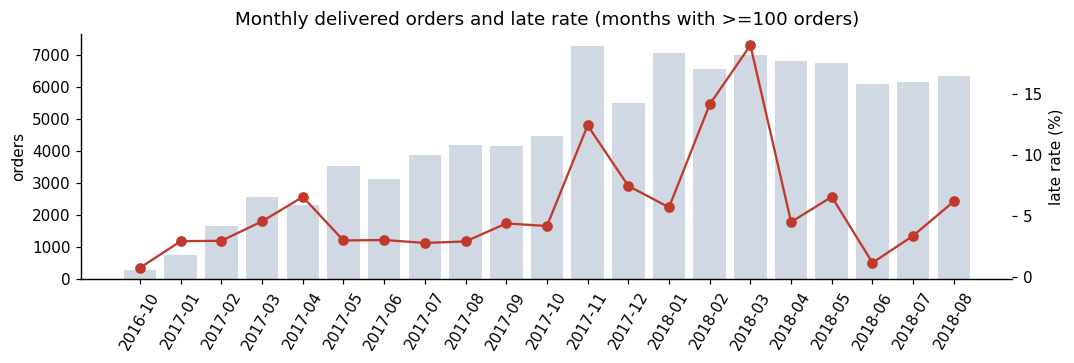

ym,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders,1.0,265.00,1.0,750.00,1653.00,2546.00,2303.00,3545.00,3135.00,3872.00,4193.00,4150.00,4478.00,7288.0,5513.00,7069.0,6555.00,7003.00,6798.0,6749.00,6096.00,6156.00,6351.00
late_rate,100.0,0.75,0.0,2.93,2.96,4.56,6.56,2.99,3.03,2.79,2.91,4.39,4.18,12.4,7.46,5.7,14.13,18.96,4.5,6.56,1.16,3.38,6.19


In [18]:
d = o[dlv].assign(late=lab.loc[dlv, "late_day"].astype(float), ym=o.loc[dlv, "order_purchase_timestamp"].dt.to_period("M"))
monthly = d.groupby("ym").agg(orders=("late", "size"), late_rate=("late", "mean"))
fig, ax = plt.subplots(figsize=(10, 3.4))
m = monthly[monthly.orders >= 100]
ax.bar(m.index.astype(str), m.orders, color="#cfd8e3", label="delivered orders")
ax2 = ax.twinx(); ax2.plot(m.index.astype(str), m.late_rate * 100, color="#c0392b", marker="o", label="late rate %")
ax.set_ylabel("orders"); ax2.set_ylabel("late rate (%)"); ax.tick_params(axis="x", rotation=60)
ax.set_title("Monthly delivered orders and late rate (months with >=100 orders)")
fig.tight_layout(); fig.savefig(C.FIGURES_DIR / "01_monthly_late_rate.png"); plt.show()
monthly.assign(late_rate=lambda x: (x.late_rate * 100).round(2)).T

**Question.** Is the late rate stable over time?
**Finding.** No. It ranges from about 1% to about 19% between months, with spikes in Nov 2017 (Black Friday) and Feb–Mar 2018. 2016 is nearly empty: a few hundred orders and a gap in Nov–Dec.
**Implication.** A random split would hide this drift, so the split must be chronological and the evaluation per month. Base-rate shifts also mean probabilities need calibrating on the most recent pre-test period. 2016 is too sparse to be training rows, but its orders can still seed seller history.

### 7.3 Right-censoring at the end of the data
Question: which recent orders have an outcome we can actually observe?

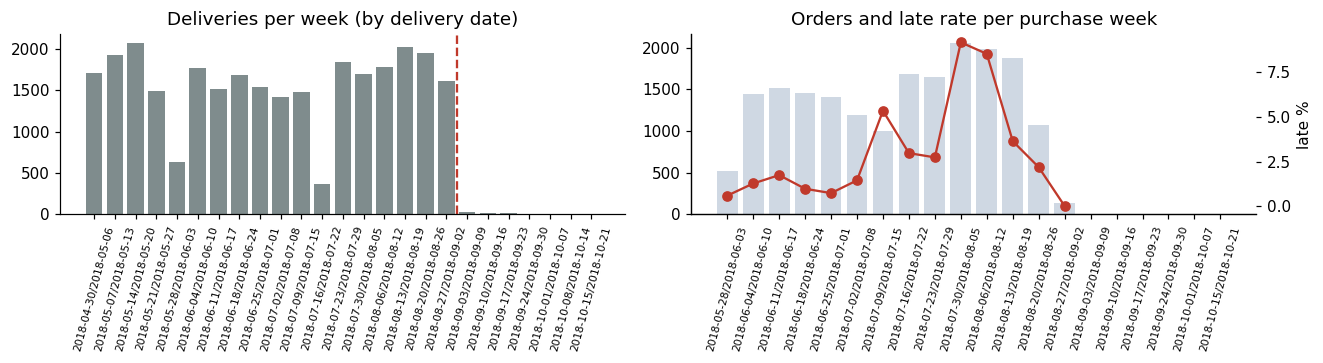

deliveries per week around the cutoff: {Period('2018-08-13/2018-08-19', 'W-SUN'): 2021, Period('2018-08-20/2018-08-26', 'W-SUN'): 1944, Period('2018-08-27/2018-09-02', 'W-SUN'): 1607, Period('2018-09-03/2018-09-09', 'W-SUN'): 28, Period('2018-09-10/2018-09-16', 'W-SUN'): 10, Period('2018-09-17/2018-09-23', 'W-SUN'): 10, Period('2018-09-24/2018-09-30', 'W-SUN'): 2, Period('2018-10-01/2018-10-07', 'W-SUN'): 1, Period('2018-10-08/2018-10-14', 'W-SUN'): 1, Period('2018-10-15/2018-10-21', 'W-SUN'): 1}


,orders,delivered,late_rate
wk,,,
2018-08-20/2018-08-26,1071,1054,2.18
2018-08-27/2018-09-02,130,116,0.00
2018-09-03/2018-09-09,7,0,NaN
2018-09-10/2018-09-16,4,0,NaN
2018-09-17/2018-09-23,2,0,NaN
2018-09-24/2018-09-30,3,0,NaN
2018-10-01/2018-10-07,2,0,NaN
2018-10-15/2018-10-21,2,0,NaN


In [19]:
dd = o[o.order_delivered_customer_date.notna()]
wk_deliv = dd.groupby(dd.order_delivered_customer_date.dt.to_period("W")).size()
recent = o[o.order_purchase_timestamp >= "2018-06-01"].copy()
recent["late"] = lab.loc[recent.index, "late_day"].astype(float)
recent["wk"] = recent.order_purchase_timestamp.dt.to_period("W")
wk_purch = recent.groupby("wk").agg(orders=("order_id", "size"),
                                    delivered=("order_status", lambda s: (s == "delivered").sum()),
                                    late_rate=("late", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
w = wk_deliv[wk_deliv.index >= pd.Period("2018-05-01", "W")]
axes[0].bar(w.index.astype(str), w.values, color="#7f8c8d"); axes[0].axvline(list(w.index).index(pd.Period(C.T_OBS, "W")) - 0.5, color="#c0392b", ls="--")
axes[0].set_title("Deliveries per week (by delivery date)"); axes[0].tick_params(axis="x", rotation=75, labelsize=7)
axes[1].bar(wk_purch.index.astype(str), wk_purch.orders, color="#cfd8e3")
a2 = axes[1].twinx(); a2.plot(wk_purch.index.astype(str), wk_purch.late_rate * 100, color="#c0392b", marker="o")
axes[1].set_title("Orders and late rate per purchase week"); axes[1].tick_params(axis="x", rotation=75, labelsize=7); a2.set_ylabel("late %")
fig.tight_layout(); fig.savefig(C.FIGURES_DIR / "01_censoring.png"); plt.show()
print("deliveries per week around the cutoff:", w.loc[pd.Period("2018-08-13","W"):].to_dict())
wk_purch.tail(8).assign(late_rate=lambda x: (x.late_rate * 100).round(2))

In [20]:
est_ok = (o.order_estimated_delivery_date <= C.T_OBS)
share = o.groupby(o.order_purchase_timestamp.dt.to_period("M")).apply(lambda g: est_ok[g.index].mean() * 100, include_groups=False)
print("share of orders whose promised date is <= T_OBS, by purchase month:", share.loc["2018-05":].round(1).to_dict())
open_ = o[o.order_status.isin(["shipped", "invoiced", "processing", "approved", "created"])]
snapshot = o[C.ORDER_TS_COLS[:4]].max().max()
print(f"\nnon-cancelled orders never delivered: {len(open_):,} by status {open_.order_status.value_counts().loc[lambda s: s>0].to_dict()}")
print(f"... of which promised date already passed at snapshot {snapshot}: {(open_.order_estimated_delivery_date < snapshot).sum():,}")
print("cancelled/unavailable orders:", o.order_status.isin(["canceled", "unavailable"]).sum())

share of orders whose promised date is <= T_OBS, by purchase month: {Period('2018-05', 'M'): 100.0, Period('2018-06', 'M'): 100.0, Period('2018-07', 'M'): 99.1, Period('2018-08', 'M'): 73.8, Period('2018-09', 'M'): 0.0, Period('2018-10', 'M'): 0.0}

non-cancelled orders never delivered: 1,729 by status {'shipped': 1107, 'invoiced': 314, 'processing': 301, 'created': 5, 'approved': 2}
... of which promised date already passed at snapshot 2018-10-17 17:30:00: 1,729
cancelled/unavailable orders: 1234


**Finding.**
1. Recorded deliveries stop abruptly: hundreds to thousands per week until the week of 27 Aug–2 Sep 2018, then a trickle. The **effective observation cutoff is `T_OBS = 2018-09-03`**.
2. Orders purchased in the last weeks of August are almost all short-promise, fast deliveries. Their late rate falls steadily towards 0%, so slow orders are *missing*, not *absent*. This is right-censoring.
3. Every non-cancelled order that was never delivered (1,729) is already past its promise. These orders are **known failures** that a "delivered only" filter silently drops.

**Decision (provisional, finalised in Stage 3).**
* Training and evaluation rows are delivered orders purchased **2017-01-01 → 2018-07-31** whose promised date is ≤ `T_OBS`.
* August 2018 is excluded as censored. 2016 is excluded as sparse, but its orders still feed history features.
* Sensitivity label `promise_failed`: also counts the never-delivered, non-cancelled orders as positive.
* Cancelled and unavailable orders are excluded, because their outcome is a different event.

## 8. Reviews (secondary analysis only)

In [21]:
r = rv.merge(o[["order_id", "order_status", "order_delivered_customer_date", "order_estimated_delivery_date"]], on="order_id", validate="m:1")
rd = r[r.order_status == "delivered"].copy()
print("score distribution %:", (rv.review_score.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print("review_creation_date carries a time-of-day in", int((rv.review_creation_date != rv.review_creation_date.dt.normalize()).sum()), "rows")
print("reviews created before delivery - timestamp comparison:", int((rd.review_creation_date < rd.order_delivered_customer_date).sum()),
      "| day-level comparison:", int((rd.review_creation_date < rd.order_delivered_customer_date.dt.normalize()).sum()))
rd["late"] = rd.order_delivered_customer_date.dt.normalize() > rd.order_estimated_delivery_date
rd["bad"] = rd.review_score <= 2
rd.groupby("late").agg(reviews=("bad", "size"), mean_score=("review_score", "mean"), bad_review_rate=("bad", "mean")).round(3)

score distribution %: {1: 11.5, 2: 3.2, 3: 8.2, 4: 19.3, 5: 57.8}
review_creation_date carries a time-of-day in 85 rows
reviews created before delivery - timestamp comparison: 8319 | day-level comparison: 5126


,reviews,mean_score,bad_review_rate
late,,,
False,89952,4.290,0.093
True,6409,2.271,0.624


**Finding.** Review dates are date-only, so comparing them with a delivery *timestamp* exaggerates how many reviews were "written before delivery". The day-level count is the defensible one. Late orders receive much worse reviews.

**Implication.** Reviews are **excluded from Task A**: they exist only after delivery, so using them is leakage. The late→bad-review association is reported as descriptive evidence, not as a causal effect. Task B is deferred until Task A is complete.

## 9. Column availability at the Task A prediction moment (checkout)

In [22]:
avail = pd.DataFrame([
    ("orders", "order_purchase_timestamp", "checkout", "yes (calendar features, as-of anchor)"),
    ("orders", "order_estimated_delivery_date", "checkout (shown to customer)", "yes (promised_days)"),
    ("orders", "order_approved_at", "after payment approval", "no"),
    ("orders", "order_delivered_carrier_date", "dispatch", "no"),
    ("orders", "order_delivered_customer_date", "delivery", "no (target only)"),
    ("orders", "order_status", "final state", "no (population filter only)"),
    ("items", "price, freight_value, product_id, seller_id", "checkout", "yes (aggregated)"),
    ("items", "shipping_limit_date", "after approval (~approval + 6 days)", "no"),
    ("products", "category, weight, dimensions, photos, name/description length", "catalogue (static)", "yes"),
    ("customers / sellers", "zip prefix, city, state", "checkout", "yes"),
    ("geolocation", "lat/lng via zip map", "static", "yes (distance)"),
    ("payments", "payment_type, installments, n methods", "checkout", "yes (ablation-gated)"),
    ("payments", "payment_value", "checkout", "redundant with price + freight"),
    ("reviews", "all columns", "after delivery", "no (secondary analysis only)"),
    ("derived", "seller / route historical late rate", "as-of purchase time", "yes, only using orders whose label was known before purchase"),
], columns=["table", "column(s)", "known when", "Task A input?"])
avail

,table,column(s),known when,Task A input?
0,orders,order_purchase_timestamp,checkout,"yes (calendar features, as-of anchor)"
1,orders,order_estimated_delivery_date,checkout (shown to customer),yes (promised_days)
2,orders,order_approved_at,after payment approval,no
3,orders,order_delivered_carrier_date,dispatch,no
4,orders,order_delivered_customer_date,delivery,no (target only)
5,orders,order_status,final state,no (population filter only)
6,items,"price, freight_value, product_id, seller_id",checkout,yes (aggregated)
7,items,shipping_limit_date,after approval (~approval + 6 days),no
8,products,"category, weight, dimensions, photos, name/des...",catalogue (static),yes
9,customers / sellers,"zip prefix, city, state",checkout,yes


## 10. Population funnel (provisional)

In [23]:
steps = [("all orders", pd.Series(True, index=o.index))]
steps.append(("status delivered & delivery date present", steps[-1][1] & dlv))
steps.append(("purchase >= 2017-01-01", steps[-1][1] & (o.order_purchase_timestamp >= C.POPULATION_START)))
steps.append(("purchase < 2018-08-01", steps[-1][1] & (o.order_purchase_timestamp < C.POPULATION_END)))
steps.append(("promised date <= T_OBS", steps[-1][1] & est_ok))
funnel = pd.DataFrame([{"step": s, "orders": int(m.sum()), "late_day": int(lab.loc[m, "late_day"].sum()),
                        "late_rate_%": round(lab.loc[m, "late_day"].mean() * 100, 2)} for s, m in steps])
funnel["removed"] = funnel.orders.shift(1) - funnel.orders
funnel

,step,orders,late_day,late_rate_%,removed
0,all orders,99441,6535,6.77,NaN
1,status delivered & delivery date present,96470,6534,6.77,2971.0
2,purchase >= 2017-01-01,96203,6531,6.79,267.0
3,purchase < 2018-08-01,89852,6138,6.83,6351.0
4,promised date <= T_OBS,89795,6138,6.84,57.0


## 11. Proposal estimates vs. values verified here

In [24]:
carrier_lt_purchase_all = int((o.order_delivered_carrier_date < o.order_purchase_timestamp).sum())
verified = pd.DataFrame([
    ("orders", "99,441", f"{len(o):,}"),
    ("delivered orders with date", "96,470", f"{dlv.sum():,}"),
    ("late (day rule)", "6,534 (6.77%)", f"{int(lab.loc[dlv,'late_day'].sum()):,} ({lab.loc[dlv,'late_day'].mean():.2%})"),
    ("late (timestamp rule)", "7,826 (8.11%)", f"{int(lab.loc[dlv,'late_ts'].sum()):,} ({lab.loc[dlv,'late_ts'].mean():.2%})"),
    ("monthly late-rate range", "1.4% - 21.4%", f"day rule {m.late_rate.min():.2%} - {m.late_rate.max():.2%} (months with >=100 orders); the proposal's range matches the timestamp rule"),
    ("geolocation exact duplicate rows", "261,831", "261,831 (full-row; see 6.3)"),
    ("geolocation points outside Brazil", "42", f"{geo_outside} raw rows ({zstats['outside_brazil_dropped']} after dedup)"),
    ("orders with >1 review / no review", "547 / 768", f"{(rv_per_order>1).sum():,} / {(~o.order_id.isin(rv.order_id)).sum():,}"),
    ("reviews created before delivery", "8,320", f"{int((rd.review_creation_date < rd.order_delivered_customer_date).sum()):,} vs timestamp, but {int((rd.review_creation_date < rd.order_delivered_customer_date.dt.normalize()).sum()):,} at day level"),
    ("carrier handoff before purchase", "166", f"{carrier_lt_purchase_all:,} (all orders)"),
    ("delivered before carrier handoff", "23", f"{int(anom.loc['delivered < carrier handoff','n_orders'])}"),
    ("carrier handoff before approval", "not mentioned", f"{int(anom.loc['carrier handoff < approval','n_orders']):,}"),
    ("multi-seller orders", "1,278", f"{(items_per_order.n_sellers>1).sum():,}"),
    ("repeat customers", "2,997", f"{(T['customers'].customer_unique_id.value_counts()>1).sum():,}"),
    ("mean review score late / on-time", "2.57 / 4.31", " / ".join(f"{v:.2f}" for v in rd.groupby('late').review_score.mean().reindex([True, False]))),
    ("missing customer coords", "279 zips -> state centroid", f"{int(cov.loc[cov.index!='zip5','customers'].sum())} customers unmatched: {int(cov.loc['zip3','customers'])} recovered via 3-digit prefix, {int(cov.loc['state','customers'])} via state"),
    ("untranslated categories", "2", str(len(cats - set(tr.product_category_name)))),
    ("timestamp format", "assumed ISO", "orders/items are DD-MM-YYYY HH:MM (no seconds)"),
    ("censoring treatment", "drop 'last weeks'", "data-driven T_OBS = 2018-09-03; Aug 2018 excluded; 1,729 open orders = known failures"),
], columns=["item", "proposal (prior estimate)", "verified on supplied data"])
verified

,item,proposal (prior estimate),verified on supplied data
0,orders,"99,441","99,441"
1,delivered orders with date,"96,470","96,470"
2,late (day rule),"6,534 (6.77%)","6,534 (6.77%)"
3,late (timestamp rule),"7,826 (8.11%)","7,826 (8.11%)"
4,monthly late-rate range,1.4% - 21.4%,day rule 0.75% - 18.96% (months with >=100 ord...
5,geolocation exact duplicate rows,"261,831","261,831 (full-row; see 6.3)"
6,geolocation points outside Brazil,42,42 raw rows (33 after dedup)
7,orders with >1 review / no review,547 / 768,547 / 768
8,reviews created before delivery,"8,320","8,319 vs timestamp, but 5,126 at day level"
9,carrier handoff before purchase,166,161 (all orders)


## 12. Recommendation: tables for the primary (Task A) pipeline

| Table | Class | Use |
|---|---|---|
| orders | **Essential** | Label, purchase time, promise, population filter |
| order_items | **Essential** | Aggregated to order grain: value, freight, item / seller counts, seller link |
| customers | **Essential** | Destination zip and state (1:1 with orders) |
| sellers | **Essential** | Origin zip and state, for distance and route |
| products | **Useful** | Weight, volume, category, aggregated over items |
| geolocation | **Useful, via compact zip map only** | Coordinates → distance; never joined raw |
| payments | **Useful, ablation-gated** | Main payment type, installments, n methods (checkout-time) |
| reviews | **Exclude from Task A** | Post-delivery (leakage); secondary association analysis only |
| translation | **Optional (presentation)** | English labels for figures; not a model input |

Full reasoning: `reports/01_table_selection.md`. **Stage 3 (order-level dataset and as-of history features) starts only after review.**

In [25]:
print(f"notebook runtime {time.perf_counter()-T0:.1f}s | final RSS {rss()}")

notebook runtime 15.6s | final RSS 357 MB
